# PHYS 2550 — Homework 2

In this notebook I compare fully connected and convolutional neural networks using the Galaxy10 SDSS images. I start by looking at the data and deciding how to preprocess it. I then train the models and check how their predictions change when I shift the galaxies, scramble the pixels, or add noise.

I have organised the notebook to follow the homework, with the calculations and results explained as I go. The report goes into more detail.

I ran all eleven models and the remaining evaluations on a **Tesla T4 GPU** in Colab on 15 October 2026. The outputs below are from that run.

## Setup

I used the same Tesla T4 GPU for all training runs. I synchronised CUDA before each timing measurement so the GPU had finished its work before I read the clock.

In [1]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, json, time, copy, hashlib, platform, random, urllib.request
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, roc_curve, auc
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True,
                     'font.size': 10, 'axes.spines.top': True,
                     'axes.spines.right': True, 'savefig.dpi': 170})

In [3]:
RUN_MODE = 'auto'
BASE = Path('/content/drive/MyDrive/PHYS2550/Homework 2') if IN_COLAB else Path.cwd()
BASE = Path(os.environ.get('HW2_BASE_DIR', str(BASE))).resolve()
HAS_CUDA = torch.cuda.is_available()
MODE = ('gpu' if HAS_CUDA else 'review') if RUN_MODE == 'auto' else RUN_MODE
if MODE not in {'gpu', 'review'}:
    raise ValueError('Choose auto, gpu, or review.')
if MODE == 'gpu' and not HAS_CUDA:
    raise RuntimeError('GPU run requested, but CUDA is unavailable. Select a GPU kernel/runtime.')
if IN_COLAB and MODE == 'review' and RUN_MODE == 'auto':
    raise RuntimeError('Colab has not allocated a GPU. Change runtime type to GPU, then Run all.')

DATA = BASE
if MODE == 'gpu':
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    ROOT = BASE / 'gpu_runs' / run_id
else:
    ROOT = BASE
    if not (ROOT / 'results' / 'metrics.csv').exists():
        raise RuntimeError('Review mode needs the saved results folder. Use a CUDA GPU for a new run.')
FIG = ROOT / 'report' / 'figures'
RESULT = ROOT / 'results'
CHECK = ROOT / 'checkpoints'
for folder in (DATA, FIG, RESULT, CHECK):
    folder.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if MODE == 'gpu' else 'cpu')
SEEDS, SPLIT_SEED = [11, 22, 33], 2550
NAMES = ['Face-on, no spiral','Smooth, round','Smooth, intermediate','Smooth, cigar',
         'Edge-on, rounded bulge','Edge-on, boxy bulge','Edge-on, no bulge',
         'Tight spiral','Medium spiral','Loose spiral']

In [4]:
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close()

def savejson(obj, name):
    (RESULT/name).write_text(json.dumps(obj, indent=2,
        default=lambda x: x.item() if hasattr(x, 'item') else str(x)))

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(seed)

def sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
hardware = dict(platform=platform.platform(), device=str(DEVICE),
    gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'None',
    torch=torch.__version__, numpy=np.__version__, mode=MODE)
if MODE == 'gpu':
    savejson(hardware, 'hardware.json')
else:
    hardware = json.loads((RESULT/'hardware.json').read_text())
RESULT_LABEL = 'GPU rerun' if MODE == 'gpu' else ('Saved GPU experiment' if hardware['device'] == 'cuda' else 'Earlier CPU experiment')
display(pd.DataFrame([{'status': RESULT_LABEL, **hardware}]))
print('Result folder:', ROOT)

,status,platform,device,gpu,torch,numpy,mode
0,GPU rerun,Linux-6.6.122+-x86_64-with-glibc2.39,cuda,Tesla T4,2.11.0+cu130,2.1.3,gpu


Result folder: /content/drive/MyDrive/PHYS2550/Homework 2/gpu_runs/20261016T015510176455Z


## Part 1: Theory (30 points)

I worked through these calculations before the experiments. Later I check the parameter totals against the models in the code.

### T1. Counting parameters.

For a dense layer, I count $(n+1)m$ parameters, including the biases. For a convolution, the count is $(k_hk_wC_{in}+1)C_{out}$.

| Model | Parameters by trainable layer | Total |
|---|---|---:|
| CNN | 448; 4,640; 18,496; 147,520; 650 | 171,754 |
| FCNN-matched | 165,912; 1,600; 650 | 168,162 |
| FCNN-large | 1,769,728; 32,896; 1,290 | 1,803,914 |

Most of the CNN's parameters are actually in its first dense layer: approximately 85.9%. In the FCNN, each node in the first layer needs 6,913 parameters, so just 24 nodes already use nearly the same budget as the whole CNN.

### T2. Convolution and pooling by hand.

#### (a)

Using the supplied input and sharpening kernel, I get the following output for stride 1 without padding:

$$\begin{bmatrix}11&-4&6\\-4&15&-4\\-5&2&9\end{bmatrix}.$$

#### (b)

The output-size formula is $\lfloor(N+2p-k)/s\rfloor+1$: padding 1 gives $5\times5$, and stride 2 without padding gives $2\times2$. 

#### (c)

Applying $2\times2$ pooling with stride 1 gives

$$M=\begin{bmatrix}15&15\\15&15\end{bmatrix},\qquad
A=\begin{bmatrix}4.5&3.25\\2&5.5\end{bmatrix}.$$

If I move the bright pixel, its response and the responses around it change. Max pooling can keep the same peak while it stays inside a window, whereas average pooling spreads its contribution. Once the pixel moves between windows, neither output is guaranteed to stay the same.

#### (d)

The kernel entries sum to one, so a constant sky level stays unchanged. However, I get $\sum K^2=29$ for independent noise, which means the noise standard deviation increases by $\sqrt{29}$. I would therefore be careful about sharpening faint galaxies.

#### (e)

This kernel is unchanged by a 180-degree flip. For a learned kernel, flipping changes the arrangement of the weights, but the network can still learn the same family of filters.

### T3. Shapes and receptive field.

#### (a)

Following the image through the convolution and pooling layers, I get:

$$48\times48\times3\to48\times48\times16\to24\times24\times16
\to24\times24\times32\to12\times12\times32
\to12\times12\times64\to6\times6\times64.$$

ReLU preserves each convolution's shape. Flattening gives 2,304 values, followed by 64 units, ReLU, dropout (both still 64), and 10 logits. 

#### (b)

Using $r'=r+(k-1)j$ and $j'=sj$, the third convolution sees $18\times18$ input pixels and the final pool sees $22\times22$. The third convolution therefore cannot see a whole typical 20–40 pixel galaxy at once. The final pool can cover a small one if it is suitably aligned, and the dense head combines information from all positions. 

#### (c)

If I instead used stride 2 without padding in the first layer, its output would be $23\times23\times16$.

### T4. Equivariance and invariance.

#### (a)

Equivariance means $f(T_\delta x)=T_\delta f(x)$; invariance means $f(T_\delta x)=f(x)$. Ignoring boundaries,

$$[K\star T_\delta x](u)=\sum_v K(v)x(u+v-\delta)
=[T_\delta(K\star x)](u).$$

#### (b)

Shared convolutional filters and pointwise ReLU preserve equivariance. Pooling gives limited tolerance to small shifts; strides, boundaries and the dense head prevent exact invariance. 

#### (c)

An unconstrained FCNN does not build in either property. I expect both models to become less accurate when I shift the crops, but I expect the CNN to cope better.

### T5. Scrambled pixels.

A fixed pixel permutation preserves the values but changes their neighbours. An FCNN can absorb it into its first-layer weights after retraining. The CNN filters would no longer see the original neighbouring pixels, so I expect scrambling to hurt the CNN more. I test this prediction in Part 3.3.

### T6. Parameters are not compute.

#### (a)

For one forward pass, I get the following MAC counts. For each convolution I use output height × output width × $C_{out}$ × $k^2C_{in}$; for a dense layer I multiply its input and output sizes.

| Model | Forward MACs per image |
|---|---:|
| CNN | 6,451,840 |
| FCNN-matched | 168,064 |
| FCNN-large | 1,803,520 |

#### (b)

I get about 38.4 times as many forward MACs for the CNN as for the matched FCNN. Sharing weights reduces the parameter count, but those weights are still used at many image positions. I would not expect this ratio to translate directly into training time, since training also includes backward operations and depends on the hardware.

#### (c)

A CNN could still reach a given validation accuracy in fewer epochs. To check whether that also means less time, I would measure seconds per epoch, epochs to a common target, and total seconds to that target on the same GPU.

### T7. Pooling and noise.

#### (a)

For four independent sky pixels, average pooling has mean $\mu$ and standard deviation $\sigma/2$. 

#### (b)

Gaussian max pooling is biased upward, with mean approximately $\mu+1.03\sigma$. 

#### (c)

Min pooling suits a dark object on a light background. For a faint extended galaxy I would consider average pooling first, although the required experiment retains the specified max pooling.

### T8. Reading training curves.

#### (a)

In the supplied curves, I can see that FCNN-large is overfitting. I would use early stopping to select the validation minimum near epoch 8. The CNN does not show the same clear overfitting, although a small gap between the curves does not tell me that its remaining error is unavoidable. 

#### (b)

Weight decay discourages large weights; dropout reduces dependence on particular hidden units. Both can reduce overfitting. 

#### (c)

The CNN's shared local filters constrain the functions it can learn in a way suited to images.

## Part 2: Data and preprocessing (25 points)

### 2.1 First look.

I used the original Galaxy10 SDSS file and checked its checksum before loading it. Below I check the image dimensions, pixel values and number of images in each class.

I then split the data into training, validation and test sets, keeping approximately the same class proportions in each. I use only the training images to investigate the data and fit the preprocessing. The validation set is used to select the models, and I leave the test set until the final evaluation.

In [6]:
datafile = DATA / 'Galaxy10.h5'
uploaded = Path('/content/Galaxy10.h5')
if not datafile.exists() and uploaded.exists():
    import shutil
    assert hashlib.sha256(uploaded.read_bytes()).hexdigest() == '969a6b1cefcc36e09fffa86febd2f699a4aa19b837ba0427f01b0bc6ded458af', 'Wait for the dataset upload to finish, then rerun this cell.'
    shutil.copy2(uploaded, datafile)
if not datafile.exists():
    temporary=datafile.with_suffix('.part')
    urllib.request.urlretrieve('https://zenodo.org/records/10844811/files/Galaxy10.h5', temporary)
    temporary.replace(datafile)
digest=hashlib.sha256(datafile.read_bytes()).hexdigest()
assert digest == '969a6b1cefcc36e09fffa86febd2f699a4aa19b837ba0427f01b0bc6ded458af', 'Dataset checksum differs: remove the cached file and download the original SDSS file again.'
with h5py.File(datafile,'r') as f:
    images=f['images'][:]; labels=f['ans'][:].astype(np.int64)
idx=np.arange(len(labels))
train_idx, held_idx=train_test_split(idx,test_size=.30,stratify=labels,random_state=SPLIT_SEED)
val_idx,test_idx=train_test_split(held_idx,test_size=.5,stratify=labels[held_idx],random_state=SPLIT_SEED)
assert not (set(train_idx)&set(val_idx) or set(train_idx)&set(test_idx) or set(val_idx)&set(test_idx))
np.savez(RESULT/'split_indices.npz',train=train_idx,validation=val_idx,test=test_idx)
counts=pd.DataFrame({'class':range(10),'morphology':NAMES,'all':np.bincount(labels,minlength=10),
 'train':np.bincount(labels[train_idx],minlength=10),'validation':np.bincount(labels[val_idx],minlength=10),
 'test':np.bincount(labels[test_idx],minlength=10)})
counts.to_csv(RESULT/'class_counts.csv',index=False)
print('Shape, dtype, range:', images.shape,images.dtype,int(images.min()),int(images.max()))
print('Labels:',labels.shape,labels.dtype)
display(counts)

Shape, dtype, range: (21785, 69, 69, 3) uint8 0 255
Labels: (21785,) int64


,class,morphology,all,train,validation,test
0,0,"Face-on, no spiral",3461,2423,519,519
1,1,"Smooth, round",6997,4898,1049,1050
2,2,"Smooth, intermediate",6292,4404,944,944
3,3,"Smooth, cigar",349,244,52,53
4,4,"Edge-on, rounded bulge",1534,1074,230,230
5,5,"Edge-on, boxy bulge",17,12,3,2
6,6,"Edge-on, no bulge",589,412,89,88
7,7,Tight spiral,1121,785,168,168
8,8,Medium spiral,906,634,136,136
9,9,Loose spiral,519,363,78,78


#### Initial observations

I kept all ten classes, but the counts are very uneven. Class 5 has only 17 images in total and just two in the test set. Classes 3, 6 and 9 are also relatively small. This means that a model could get a high overall accuracy while still doing poorly on the less common galaxies. I therefore also calculate balanced accuracy, which gives each class's recall equal weight.

I found 349 class-3 images in the downloaded file, compared with 394 listed in the documentation. I use the count from the file here. The grid below shows three training examples from each class.

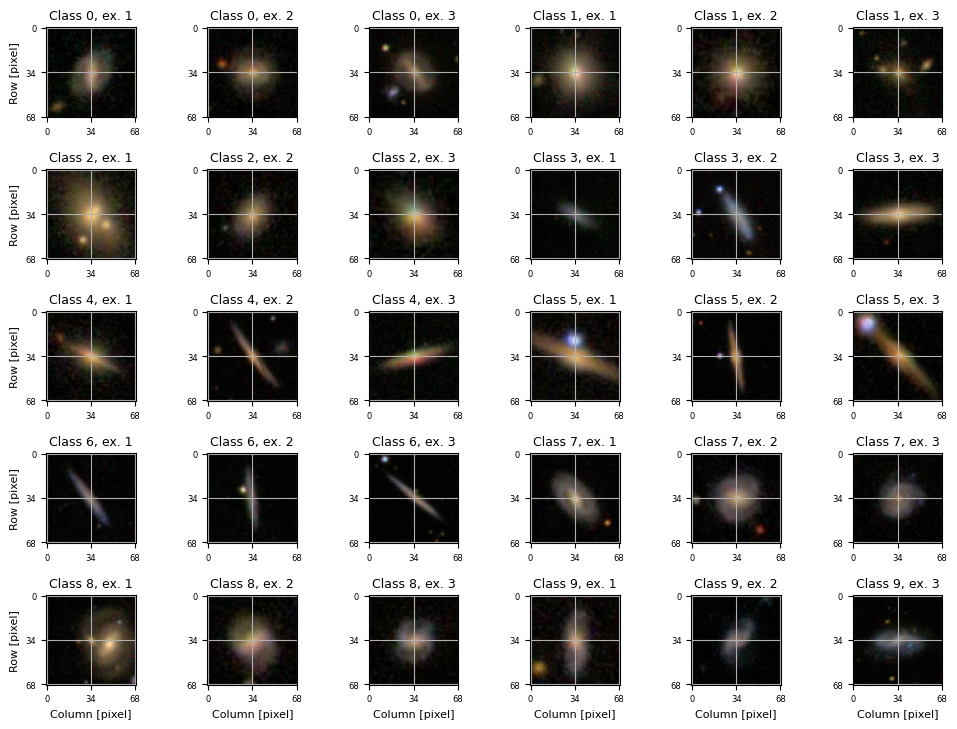

In [7]:
fig,axs=plt.subplots(5,6,figsize=(10,7.4))
for c in range(10):
    for j,k in enumerate(train_idx[labels[train_idx]==c][:3]):
        ax=axs[c//2,(c%2)*3+j]
        ax.imshow(images[k]); ax.set_xticks([0,34,68]);ax.set_yticks([0,34,68])
        ax.tick_params(labelsize=6)
        if c//2==4:ax.set_xlabel('Column [pixel]',fontsize=8)
        if (c%2)*3+j==0:ax.set_ylabel('Row [pixel]',fontsize=8)
        ax.set_title(f'Class {c}, ex. {j+1}',fontsize=9)
savefig('class_examples')

### 2.2 Is the dataset noisy?

#### (a) Sky noise.

I used the outer four pixels of each image as a sample of the sky background. For each band, I take the median of these pixels as the background level and compare two estimates of the noise: the standard deviation and $1.4826\,\mathrm{MAD}$. MAD is the median absolute deviation from the median.

I included the MAD estimate because a bright neighbouring object can increase the standard deviation quite strongly. Galaxy light extending into the border can have the same effect. The function below also calculates the aperture flux and checks for saturated pixels and possible border sources. These measurements describe the supplied 8-bit images; I am not working with calibrated detector data.

In [8]:
yy,xx=np.mgrid[:69,:69]
border=(yy<4)|(yy>=65)|(xx<4)|(xx>=65)
radius=np.sqrt((xx-34)**2+(yy-34)**2)
aperture=radius<=8
background=np.empty((len(images),3),np.float32)
noise_std=np.empty_like(background);noise_mad=np.empty_like(background)
flux=np.empty_like(background);sat=np.empty(len(images));bright=np.zeros(len(images),bool)
def measure(indices):
    for start in range(0,len(indices),256):
        ids=indices[start:start+256];a=images[ids].astype(np.float32);b=a[:,border,:]
        med=np.median(b,axis=1);sd=b.std(axis=1);mad=1.4826*np.median(np.abs(b-med[:,None,:]),axis=1)
        background[ids]=med;noise_std[ids]=sd;noise_mad[ids]=mad
        flux[ids]=(a[:,aperture,:]-med[:,None,:]).sum(axis=1)
        sat[ids]=(a==255).mean(axis=(1,2,3))
        from scipy.ndimage import label as components
        for k,im,m,s in zip(ids,a,med,mad):
            mask=border & (im[:,:,1]>m[1]+5*max(float(s[1]),1/np.sqrt(12)))
            cc,n=components(mask)
            sizes=np.bincount(cc.ravel())[1:]
            bright[k]=bool(len(sizes) and sizes.max()>=3)
measure(train_idx)
ids=train_idx
np.savez_compressed(RESULT/'training_image_diagnostics.npz',indices=ids,background=background[ids],
 noise_std=noise_std[ids],noise_mad=noise_mad[ids],aperture_flux=flux[ids],saturated_fraction=sat[ids],border_candidate=bright[ids])
floor=1/np.sqrt(12)
snr=flux[ids]/(np.maximum(noise_mad[ids],floor)*np.sqrt(aperture.sum()))
diag={'shape':list(images.shape),'dtype':str(images.dtype),'range':[int(images.min()),int(images.max())],
      'sha256':digest,'diagnostic_n':len(ids),'aperture_pixels':int(aperture.sum()),
      'background_median':np.median(background[ids],axis=0).tolist(),
      'std_median':np.median(noise_std[ids],axis=0).tolist(),
      'mad_median':np.median(noise_mad[ids],axis=0).tolist(),
      'zero_mad_fraction':(noise_mad[ids]==0).mean(axis=0).tolist(),
      'border_candidate_fraction':float(bright[ids].mean()),'saturated_pixel_fraction':float(sat[ids].mean()),
      'images_with_saturation_fraction':float((sat[ids]>0).mean())}

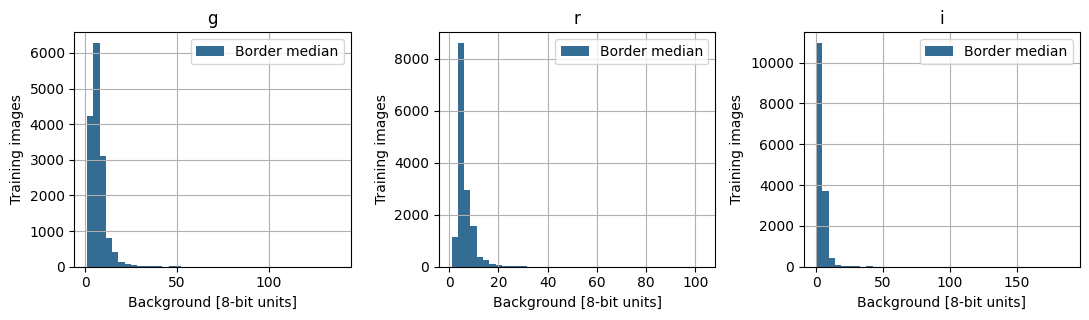

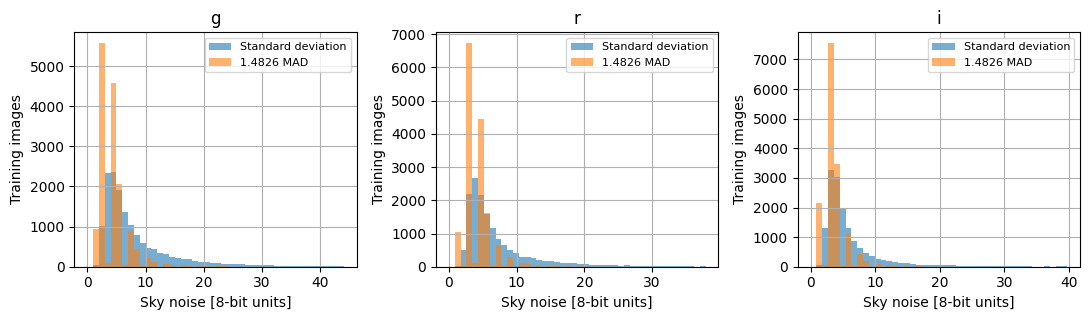

In [9]:
fig,axs=plt.subplots(1,3,figsize=(11,3.3))
for band,ax in enumerate(axs):
    ax.hist(background[ids,band],bins=40,label='Border median',color='#346c93')
    ax.set(xlabel='Background [8-bit units]',ylabel='Training images',title=['g','r','i'][band]);ax.legend()
savefig('background')
fig,axs=plt.subplots(1,3,figsize=(11,3.3))
for band,ax in enumerate(axs):
    bins=np.linspace(0,np.percentile(noise_std[ids,band],99.5),45)
    ax.hist(noise_std[ids,band],bins=bins,alpha=.6,label='Standard deviation')
    ax.hist(noise_mad[ids,band],bins=bins,alpha=.6,label='1.4826 MAD')
    ax.set(xlabel='Sky noise [8-bit units]',ylabel='Training images',title=['g','r','i'][band]);ax.legend(fontsize=8)
savefig('sky_noise')

In [10]:
display(pd.DataFrame({'band':['g','r','i'],
    'median background':diag['background_median'],
    'median standard deviation':diag['std_median'],
    'median robust sigma':diag['mad_median']}))

,band,median background,median standard deviation,median robust sigma
0,g,6.0,5.989668,4.4478
1,r,6.0,5.213939,2.9652
2,i,3.0,4.508852,2.9652


#### (b) Signal-to-noise.

I calculated the background-subtracted signal inside a circle of radius 8 pixels and divided it by an estimate of the noise in that aperture:

$$\mathrm{SNR}=\frac{\sum_{p\in A}(I_p-\mathrm{sky})}{\sigma_{sky}\sqrt{N_{pix}}}.$$

This gives me a simple way to compare the classes, although it leaves out source shot noise and assumes independent background fluctuations. Image processing can also correlate neighbouring pixels. Where the MAD is zero, I use a minimum noise estimate of $1/\sqrt{12}$ intensity units to avoid dividing by zero.

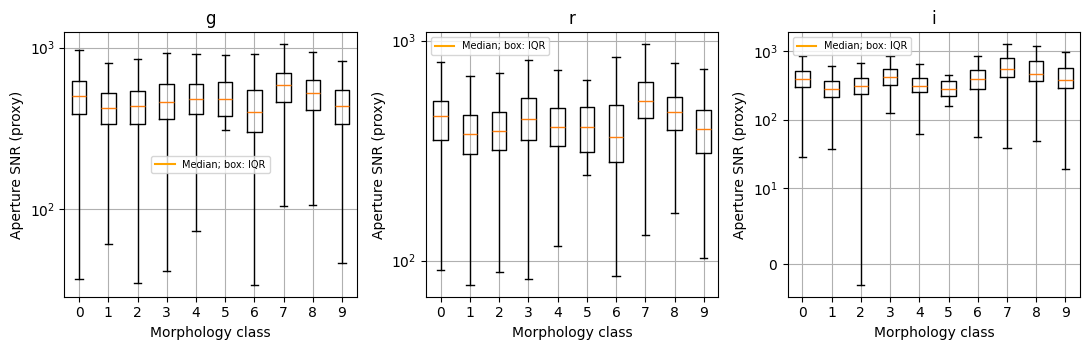

In [11]:
fig,axs=plt.subplots(1,3,figsize=(11,3.6))
snr_rows=[]
for band,ax in enumerate(axs):
    vals=[snr[labels[ids]==c,band] for c in range(10)]
    ax.boxplot(vals,showfliers=False,tick_labels=range(10));ax.set_yscale('symlog',linthresh=10)
    ax.set(xlabel='Morphology class',ylabel='Aperture SNR (proxy)',title=['g','r','i'][band])
    ax.legend(handles=[Line2D([0],[0],color='orange',label='Median; box: IQR')],fontsize=7)
    for c,v in enumerate(vals):snr_rows.append({'band':['g','r','i'][band],'class':c,'median_snr':np.median(v)})
pd.DataFrame(snr_rows).to_csv(RESULT/'snr_by_class.csv',index=False)
savefig('snr')

In [12]:
snr_table = pd.DataFrame(snr_rows)
r_medians = snr_table[snr_table.band == 'r'].sort_values('median_snr')
display(Markdown(f"I found the lowest median r-band SNR in class **{int(r_medians.iloc[0]['class'])}** "
    f"({r_medians.iloc[0].median_snr:.1f}); the highest is class "
    f"**{int(r_medians.iloc[-1]['class'])}** ({r_medians.iloc[-1].median_snr:.1f}). "
    "I would not take a lower aperture SNR to mean a lower total luminosity. Size, "
    "concentration and morphology affect the flux inside a fixed aperture."))

I found the lowest median r-band SNR in class **6** (363.5); the highest is class **7** (532.0). I would not take a lower aperture SNR to mean a lower total luminosity. Size, concentration and morphology affect the flux inside a fixed aperture.

#### (c) Contamination and digitisation.

I flagged a possible border source when at least three connected r-band pixels were more than five robust standard deviations above the border median. This gives me a repeatable check, but it can also pick up the outskirts of the galaxy itself. I would need to inspect the flagged images before treating them all as neighbouring stars.

I checked saturation separately by counting pixels with a value of 255. Below I show an example of each effect.

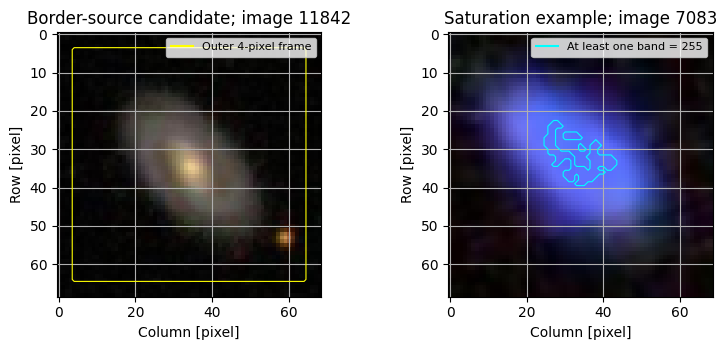

In [13]:
candidate=ids[np.where(bright[ids])[0][0]]
saturated=ids[np.argmax(sat[ids])]
fig,axs=plt.subplots(1,2,figsize=(8,3.6))
for ax,k,title in zip(axs,[candidate,saturated],['Border-source candidate','Saturation example']):
    ax.imshow(images[k]);ax.set(xlabel='Column [pixel]',ylabel='Row [pixel]',title=f'{title}; image {k}')
    if k==candidate:
        ax.contour(border.astype(float),levels=[.5],colors=['yellow'],linewidths=.8)
        ax.legend(handles=[Line2D([0],[0],color='yellow',label='Outer 4-pixel frame')],fontsize=8)
    else:
        ax.contour((images[k]==255).any(axis=2).astype(float),levels=[.5],colors=['cyan'],linewidths=.8)
        ax.legend(handles=[Line2D([0],[0],color='cyan',label='At least one band = 255')],fontsize=8)
savefig('contamination')

In [14]:
display(pd.DataFrame({'measurement':['Border-source candidates','Pixel-band values at 255',
    'Images containing at least one 255'], 'fraction':[diag['border_candidate_fraction'],
    diag['saturated_pixel_fraction'],diag['images_with_saturation_fraction']]}))

,measurement,fraction
0,Border-source candidates,0.615385
1,Pixel-band values at 255,0.000006
2,Images containing at least one 255,0.024133


Background subtraction can remove a sky offset, and cropping can exclude some neighbouring objects. However, neither fixes saturation: once different bright values have all been stored as 255, I cannot recover their original values.

#### (d) Label noise.

From the example images, I would expect confusion between round and intermediate smooth galaxies (1/2), the spiral-tightness classes (7/8/9), and the edge-on bulge classes (4/5/6). Some of these differences are difficult to see when the galaxy is faint. Agreement between volunteers helps, but I would not assume every label is correct.

This could limit how closely the predictions agree with the recorded labels. I cannot put a number on that limit from these images alone. Along with the sky noise and clipping, it is a reason why better preprocessing or a larger model may not remove every error.

### 2.3 Preprocessing pipeline.

#### (a) Crop.

The assignment uses a central 48 × 48 crop. I checked this choice by plotting the mean radial profile of the training images after subtracting the sky. I also calculated how much positive background-subtracted intensity remains inside the crop. This includes positive noise and possible neighbours, so I would not treat it as an exact fraction of the galaxy's flux.

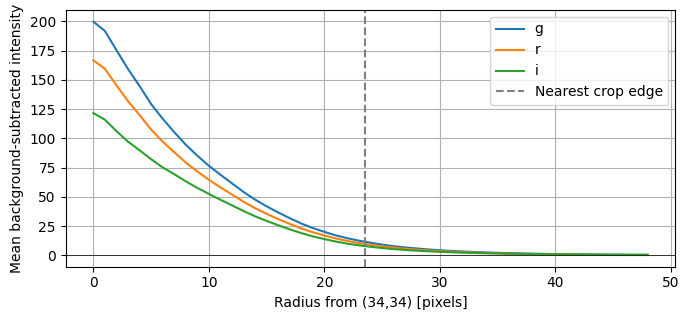

{
  "shape": [
    21785,
    69,
    69,
    3
  ],
  "dtype": "uint8",
  "range": [
    0,
    255
  ],
  "sha256": "969a6b1cefcc36e09fffa86febd2f699a4aa19b837ba0427f01b0bc6ded458af",
  "diagnostic_n": 15249,
  "aperture_pixels": 197,
  "background_median": [
    6.0,
    6.0,
    3.0
  ],
  "std_median": [
    5.989668369293213,
    5.213939189910889,
    4.508852005004883
  ],
  "mad_median": [
    4.4477996826171875,
    2.9651999473571777,
    2.9651999473571777
  ],
  "zero_mad_fraction": [
    0.0001311561413863204,
    0.0001967342120794806,
    0.000327890353465801
  ],
  "border_candidate_fraction": 0.6153846153846154,
  "saturated_pixel_fraction": 5.863137735431323e-06,
  "images_with_saturation_fraction": 0.024132730015082957,
  "positive_flux_crop_fraction": 0.8840461488115061,
  "radial_profile_r_23": [
    12.659291271084887,
    10.654612461460076,
    8.682149247299515
  ],
  "radial_profile_center": [
    199.77214899337662,
    166.71778477277198,
    121.6700767263

In [15]:
profile=np.zeros((49,3));retained=0.;total=0.
for start in range(0,len(ids),256):
    k=ids[start:start+256];a=images[k].astype(np.float32)-background[k,None,None,:]
    for r in range(49):
        mask=(radius>=r)&(radius<r+1)
        if mask.any(): profile[r]+=a[:,mask,:].mean(axis=1).sum(axis=0)
    positive=np.maximum(a,0);retained+=positive[:,10:58,10:58,:].sum(dtype=np.float64);total+=positive.sum(dtype=np.float64)
profile/=len(ids)
diag['positive_flux_crop_fraction']=retained/total
diag['radial_profile_r_23']=profile[23].tolist();diag['radial_profile_center']=profile[0].tolist()
pd.DataFrame(profile,columns=['g','r','i']).to_csv(RESULT/'radial_profile.csv',index_label='radius')
plt.figure(figsize=(7,3.3))
for b in range(3):plt.plot(range(49),profile[:,b],label=['g','r','i'][b])
plt.axvline(23.5,ls='--',color='gray',label='Nearest crop edge');plt.axhline(0,color='black',lw=.5)
plt.xlabel('Radius from (34,34) [pixels]');plt.ylabel('Mean background-subtracted intensity');plt.legend()
savefig('radial_profile');savejson(diag,'diagnostics.json');print(json.dumps(diag,indent=2),flush=True)

In [16]:
display(Markdown(f"The crop retains **{100*diag['positive_flux_crop_fraction']:.1f}%** "
    "of positive background-subtracted intensity. I keep the reference crop (rows/columns "
    "10–57): it retains the bright central structure while reducing sky area, although "
    "some outskirts are lost."))

The crop retains **88.4%** of positive background-subtracted intensity. I keep the reference crop (rows/columns 10–57): it retains the bright central structure while reducing sky area, although some outskirts are lost.

#### (b) Normalisation.

I subtract the border median from each band, then standardise using means and standard deviations calculated from the training crops:

$$x'_b=\frac{x_b-\mathrm{sky}_b-\mu_b}{s_b}.$$

I use these same constants on the validation and test images. Calculating them from all the images would let information from the held-out sets enter the preprocessing.

I did not divide each image by its brightest pixel. That would remove its overall brightness scale, and a noisy or saturated pixel could determine the divisor. Using one divisor for all three bands preserves their relative colours; dividing each band separately also removes those colour ratios.

#### (c) Background.

I subtract each image's border median before standardisation. The sky estimates in 2.2(a) show that this offset varies between images, so subtracting it helps prevent the background level from determining the input scale. It does not remove the sky fluctuations themselves.

#### (d) Class imbalance.

For the uneven class counts, I chose cross-entropy weights proportional to $1/\sqrt{n_c}$. This gives the smaller classes more influence without weighting them as strongly as $1/n_c$ would. I keep the weights and preprocessing the same for all three models.

Plain accuracy can be dominated by the largest classes, so I also report balanced accuracy, which gives each class equal weight.

In [17]:
measure(val_idx)
def raw_crops(indices, offsets=None):
    if offsets is None: a=images[indices,10:58,10:58,:].astype(np.float32)
    else: a=np.stack([images[k,10+dy:58+dy,10+dx:58+dx,:] for k,(dy,dx) in zip(indices,offsets)]).astype(np.float32)
    return a-background[indices,None,None,:]
a=raw_crops(train_idx)
mu=a.mean(axis=(0,1,2),dtype=np.float64).astype(np.float32)
sd=a.std(axis=(0,1,2),dtype=np.float64).astype(np.float32)
def preprocess(indices,offsets=None):
    x=(raw_crops(indices,offsets)-mu)/sd
    return torch.from_numpy(x.transpose(0,3,1,2).copy())
del a
xtrain=preprocess(train_idx);xval=preprocess(val_idx)
ytrain=torch.tensor(labels[train_idx]);yval=torch.tensor(labels[val_idx])
freq=np.bincount(labels[train_idx],minlength=10)
weights=np.sqrt(len(train_idx)/(10*freq));weights/=weights.mean()
criterion=nn.CrossEntropyLoss(weight=torch.tensor(weights,dtype=torch.float32,device=DEVICE))
pre={'subtract_background':True,'mean':mu.tolist(),'std':sd.tolist(),'class_weights':weights.tolist(),
     'processed_mean':xtrain.mean((0,2,3)).tolist(),'processed_std':xtrain.std((0,2,3),unbiased=False).tolist()}
savejson(pre,'preprocessing.json')
np.savez(RESULT/'preprocessing.npz',mean=mu,std=sd,weights=weights)

In [18]:
display(pd.DataFrame({'band':['g','r','i'], 'training mean':mu, 'training SD':sd,
    'processed mean':pre['processed_mean'], 'processed SD':pre['processed_std']}))

,band,training mean,training SD,processed mean,processed SD
0,g,38.869289,44.533543,3.887911e-09,1.0
1,r,32.674450,37.324928,-1.862653e-08,1.0
2,i,26.215757,31.600733,-1.716900e-08,1.0


After standardisation, I expect the training means to be close to zero and the standard deviations to be close to one. I check those values above. Below I compare a few raw colour images with their processed r-band crops. I kept a common colour scale for the processed examples so their relative brightness is still visible.

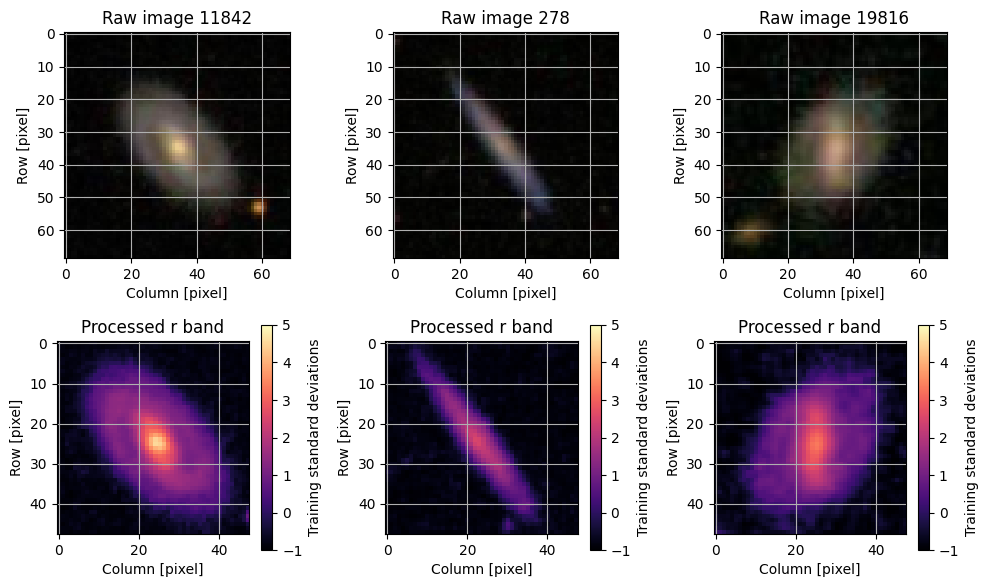

In [19]:
fig,axs=plt.subplots(2,3,figsize=(10,6))
for j,k in enumerate(train_idx[:3]):
    axs[0,j].imshow(images[k]);axs[0,j].set_title(f'Raw image {k}')
    z=preprocess(np.array([k]))[0,1].numpy()
    im=axs[1,j].imshow(z,cmap='magma',vmin=-1,vmax=5);axs[1,j].set_title('Processed r band')
    fig.colorbar(im,ax=axs[1,j],label='Training standard deviations')
    for ax in axs[:,j]:ax.set(xlabel='Column [pixel]',ylabel='Row [pixel]')
savefig('preprocessing')

### 2.4 Augmentation and the symmetries of the sky.

I would start with flips and 90-degree rotations. Turning a galaxy on the sky should not change its morphology label, and these operations do not require interpolation. A flip changes spiral handedness, but handedness is not one of the ten classes here. Other rotation angles are also physically reasonable, although interpolation changes the pixels and the crop can cut off part of the galaxy.

Small shifts would also be useful if the galaxy stays inside the crop. I would be more careful with zoom, changes to the g:r:i ratios and blurring. These change the apparent scale, colour or visibility of the structure, so I would need to justify them as possible observations of the same object.

I used **no augmentation** in the experiments below, keeping the training comparison the same for all models.

## Part 3: FCNN vs. 2D CNN on equal footing (35 points)

### 3.1 Baseline comparison.

I used the three architectures specified in the homework: a CNN, an FCNN with approximately the same number of parameters, and a larger FCNN. The CNN applies shared filters to small regions of the image, while the first FCNN layer connects to every input value.

Each model returns ten scores, one for each class. Below I check the output shapes and compare the parameter totals with my calculations in Part 1.

In [20]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(3,16,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Flatten(),
            nn.Linear(64*6*6,64),nn.ReLU(),nn.Dropout(.3),nn.Linear(64,10))
    def forward(self,x):return self.net(x)
class FCNN(nn.Module):
    def __init__(self,large=False):
        super().__init__();a,b=(256,128) if large else (24,64)
        self.net=nn.Sequential(nn.Flatten(),nn.Linear(6912,a),nn.ReLU(),nn.Linear(a,b),nn.ReLU(),nn.Dropout(.3),nn.Linear(b,10))
    def forward(self,x):return self.net(x)
BUILD={'CNN':CNN,'FCNN-matched':lambda:FCNN(False),'FCNN-large':lambda:FCNN(True)}
EXPECTED={'CNN':171754,'FCNN-matched':168162,'FCNN-large':1803914}
MACS={'CNN':6451840,'FCNN-matched':168064,'FCNN-large':1803520}
for name,make in BUILD.items():
    model=make();n=sum(p.numel() for p in model.parameters());assert n==EXPECTED[name]
    assert model(torch.zeros(2,3,48,48)).shape==(2,10)
    print(name,n,'parameters;',MACS[name],'forward MACs')

CNN 171754 parameters; 6451840 forward MACs
FCNN-matched 168162 parameters; 168064 forward MACs
FCNN-large 1803914 parameters; 1803520 forward MACs


#### Training and timing

I used Adam with a learning rate of 0.001 and batches of 128. I allowed up to 50 epochs, stopping after five epochs without an improvement in validation loss. For the final predictions I restore the weights from the lowest validation loss. I repeat the baseline runs with seeds 11, 22 and 33, keeping the data split fixed.

I time both training and validation within each epoch, but leave out file writing. CUDA is synchronised before each clock reading. One detail to keep in mind when reading the curves is that dropout is active during training and switched off during validation. The difference between these losses therefore also reflects that change in how the model is evaluated.

The functions below handle prediction, validation and training. A new GPU run trains from scratch and saves its results in a new folder.

In [21]:
def predict(model,x):
    model.eval();out=[]
    with torch.no_grad():
        for i in range(0,len(x),128):out.append(model(x[i:i+128].to(DEVICE)).softmax(1).cpu().numpy())
    return np.concatenate(out)
def evaluate_loss(model,x,y):
    model.eval();loss_sum=0.;weight_sum=0.;correct=0
    with torch.no_grad():
        for i in range(0,len(x),128):
            xb=x[i:i+128].to(DEVICE);yb=y[i:i+128].to(DEVICE);logits=model(xb)
            w=criterion.weight[yb].sum().item()
            loss_sum+=criterion(logits,yb).item()*w;weight_sum+=w
            correct+=(logits.argmax(1)==yb).sum().item()
    return loss_sum/weight_sum,correct/len(x)

In [22]:
def train_model(name,seed,xt=xtrain,xv=xval,tag='baseline'):
    stem=f'{tag}_{name}_{seed}'
    if DEVICE.type != 'cuda':
        raise RuntimeError('Training for submission requires a CUDA GPU.')
    seed_all(seed);model=BUILD[name]().to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
    loader=DataLoader(TensorDataset(xt,ytrain),batch_size=128,shuffle=True,
                      generator=torch.Generator().manual_seed(seed),num_workers=0)
    best=float('inf');best_epoch=0;stale=0;history=[];state=None;elapsed=0.
    for epoch in range(1,51):
        sync();t0=time.perf_counter();model.train();loss_sum=0.;weight_sum=0.
        for xb,yb in loader:
            xb=xb.to(DEVICE);yb=yb.to(DEVICE);optimizer.zero_grad(set_to_none=True)
            loss=criterion(model(xb),yb);loss.backward();optimizer.step()
            w=criterion.weight[yb].sum().item();loss_sum+=loss.item()*w;weight_sum+=w
        sync();train_seconds=time.perf_counter()-t0
        vl,va=evaluate_loss(model,xv,yval)
        sync();seconds=time.perf_counter()-t0;elapsed+=seconds
        row=dict(epoch=epoch,train_loss=loss_sum/weight_sum,val_loss=vl,val_accuracy=va,
                 train_seconds=train_seconds,epoch_seconds=seconds,cumulative_seconds=elapsed)
        history.append(row)
        if vl<best:
            best=vl;best_epoch=epoch;stale=0;state=copy.deepcopy(model.state_dict())
        else:stale+=1
        pd.DataFrame(history).to_csv(RESULT/(stem+'_history.csv'),index=False)
        print(f'{stem} epoch {epoch:02d}: train={row["train_loss"]:.4f} val={vl:.4f} acc={va:.4f} seconds={seconds:.2f}',flush=True)
        if stale>=5:break
    model.load_state_dict(state)
    torch.save({'state':{k:v.cpu() for k,v in state.items()},'name':name,'seed':seed,'tag':tag,
                'best_epoch':best_epoch,'best_val_loss':best},CHECK/(stem+'.pt'))
    row=dict(model=name,seed=seed,tag=tag,parameters=EXPECTED[name],macs=MACS[name],best_epoch=best_epoch,
             epochs_run=len(history),best_val_loss=best,best_val_accuracy=max(h['val_accuracy'] for h in history),
             mean_epoch_seconds=np.mean([h['epoch_seconds'] for h in history]),
             total_seconds=elapsed)
    savejson(row,stem+'_summary.json')
    del model,optimizer
    return row

In [23]:
if MODE == 'gpu':
    baseline=[]
    for seed in SEEDS:
        for name in ['FCNN-matched','FCNN-large','CNN']:
            baseline.append(train_model(name,seed))
    pd.DataFrame(baseline).to_csv(RESULT/'baseline_training.csv',index=False)

else:
    baseline = [json.loads((RESULT/f'baseline_{name}_{seed}_summary.json').read_text())
                for seed in SEEDS for name in ['FCNN-matched','FCNN-large','CNN']]
    print('Reviewing saved CPU runs; no training was performed.')
display(pd.DataFrame(baseline)[['model','seed','best_epoch','epochs_run','best_val_loss']])

baseline_FCNN-matched_11 epoch 01: train=1.8305 val=1.4143 acc=0.5499 seconds=1.04
baseline_FCNN-matched_11 epoch 02: train=1.4374 val=1.2704 acc=0.6065 seconds=0.52
baseline_FCNN-matched_11 epoch 03: train=1.2705 val=1.1968 acc=0.6120 seconds=0.52
baseline_FCNN-matched_11 epoch 04: train=1.2018 val=1.1792 acc=0.6481 seconds=0.51
baseline_FCNN-matched_11 epoch 05: train=1.1609 val=1.1215 acc=0.6680 seconds=0.50
baseline_FCNN-matched_11 epoch 06: train=1.1313 val=1.1222 acc=0.6591 seconds=0.50
baseline_FCNN-matched_11 epoch 07: train=1.1060 val=1.0627 acc=0.6873 seconds=0.52
baseline_FCNN-matched_11 epoch 08: train=1.0540 val=1.0993 acc=0.6714 seconds=0.57
baseline_FCNN-matched_11 epoch 09: train=1.0578 val=1.0676 acc=0.6802 seconds=0.51
baseline_FCNN-matched_11 epoch 10: train=1.0244 val=1.0760 acc=0.6732 seconds=0.52
baseline_FCNN-matched_11 epoch 11: train=1.0175 val=1.0351 acc=0.7013 seconds=0.52
baseline_FCNN-matched_11 epoch 12: train=1.0028 val=1.0534 acc=0.6916 seconds=0.52
base

,model,seed,best_epoch,epochs_run,best_val_loss
0,FCNN-matched,11,11,16,1.035095
1,FCNN-large,11,6,11,1.040118
2,CNN,11,19,24,0.849122
3,FCNN-matched,22,13,18,1.186066
4,FCNN-large,22,8,13,1.065856
5,CNN,22,15,20,0.813796
6,FCNN-matched,33,13,18,1.084178
7,FCNN-large,33,14,19,1.042695
8,CNN,33,21,26,0.836569


#### Train the scrambled models

I also need to retrain two models for Part 3.3. I do that here, before evaluating anything on the test set, and discuss the results after the shift experiment.

I use one fixed permutation of the 2,304 pixel positions. The three bands stay together at each position, and I apply the same permutation to the training, validation and test images.

In [24]:
permutation=np.random.default_rng(2551).permutation(48*48)
np.save(RESULT/'pixel_permutation.npy',permutation)
def scramble(x):return x.reshape(len(x),3,-1)[:,:,permutation].reshape_as(x)

In [25]:
if MODE == 'gpu':
    xst=scramble(xtrain);xsv=scramble(xval)
    scrambled=[]
    for name in ['FCNN-matched','CNN']:
        scrambled.append(train_model(name,11,xst,xsv,'scrambled'))
    del xst,xsv
else:
    scrambled = [json.loads((RESULT/f'scrambled_{name}_11_summary.json').read_text())
                 for name in ['FCNN-matched','CNN']]
    print('Reviewing the two saved scrambled CPU runs.')

scrambled_FCNN-matched_11 epoch 01: train=1.8860 val=1.5909 acc=0.4639 seconds=0.52
scrambled_FCNN-matched_11 epoch 02: train=1.5201 val=1.4229 acc=0.5557 seconds=0.52
scrambled_FCNN-matched_11 epoch 03: train=1.3761 val=1.3352 acc=0.5468 seconds=0.53
scrambled_FCNN-matched_11 epoch 04: train=1.3119 val=1.2885 acc=0.5851 seconds=0.51
scrambled_FCNN-matched_11 epoch 05: train=1.2669 val=1.3025 acc=0.5918 seconds=0.57
scrambled_FCNN-matched_11 epoch 06: train=1.2457 val=1.2440 acc=0.6193 seconds=0.52
scrambled_FCNN-matched_11 epoch 07: train=1.2250 val=1.2555 acc=0.6138 seconds=0.55
scrambled_FCNN-matched_11 epoch 08: train=1.1920 val=1.3193 acc=0.5759 seconds=0.53
scrambled_FCNN-matched_11 epoch 09: train=1.1873 val=1.2336 acc=0.6132 seconds=0.53
scrambled_FCNN-matched_11 epoch 10: train=1.1566 val=1.2093 acc=0.6230 seconds=0.53
scrambled_FCNN-matched_11 epoch 11: train=1.1249 val=1.2784 acc=0.6294 seconds=0.53
scrambled_FCNN-matched_11 epoch 12: train=1.1432 val=1.2318 acc=0.6169 secon

#### Evaluate the models

With training finished, I restore each model's best validation checkpoint and calculate accuracy and balanced accuracy on the test set.

For the timing comparison, I take the highest validation accuracy reached by FCNN-matched across its three seeds as the common target. I record when each run first reaches it. Some runs never get there, so I show how many succeeded as well as the average time among those that did.

In [26]:
def load_model(name,seed,tag):
    ck=torch.load(CHECK/f'{tag}_{name}_{seed}.pt',map_location=DEVICE)
    m=BUILD[name]().to(DEVICE)
    m.load_state_dict(ck['state'])
    m.eval()
    return m

if MODE == 'gpu':
    measure(test_idx);xtest=preprocess(test_idx);ytest=labels[test_idx]
    target=max(r['best_val_accuracy'] for r in baseline if r['model']=='FCNN-matched')
    allrows=[];probabilities={}
    for r in baseline+scrambled:
        name,seed,tag=r['model'],r['seed'],r['tag'];model=load_model(name,seed,tag)
        probs=predict(model,scramble(xtest) if tag=='scrambled' else xtest)
        probabilities[(name,seed,tag)]=probs
        np.savez_compressed(RESULT/f'{tag}_{name}_{seed}_predictions.npz',probabilities=probs,labels=ytest,indices=test_idx)
        rr=dict(r,accuracy=accuracy_score(ytest,probs.argmax(1)),balanced_accuracy=balanced_accuracy_score(ytest,probs.argmax(1)))
        hist=pd.read_csv(RESULT/f'{tag}_{name}_{seed}_history.csv');hit=hist[hist.val_accuracy>=target]
        rr.update(target_val_accuracy=target,target_epoch=int(hit.iloc[0].epoch) if len(hit) else None,
                  target_seconds=float(hit.iloc[0].cumulative_seconds) if len(hit) else None)
        allrows.append(rr);del model
    metrics=pd.DataFrame(allrows);metrics.to_csv(RESULT/'metrics.csv',index=False)

    base=metrics[metrics.tag=='baseline']
    summary=base.groupby('model')[['accuracy','balanced_accuracy','mean_epoch_seconds','best_epoch','epochs_run','target_epoch','target_seconds']].agg(['mean','std','count'])
    summary.to_csv(RESULT/'summary.csv')
else:
    metrics = pd.read_csv(RESULT/'metrics.csv')
    base = metrics[metrics.tag == 'baseline']
    target = float(base.target_val_accuracy.iloc[0])
    ytest = labels[test_idx]
    probabilities = {}
    for r in baseline + scrambled:
        key = (r['model'], r['seed'], r['tag'])
        saved = np.load(RESULT/f"{r['tag']}_{r['model']}_{r['seed']}_predictions.npz")
        probabilities[key] = saved['probabilities']

In [27]:
def ms(values, scale=1):
    values = pd.Series(values).dropna() * scale
    if not len(values): return 'Not reached'
    if len(values) == 1: return f'{values.iloc[0]:.2f}'
    return f'{values.mean():.2f} ± {values.std(ddof=1):.2f}'

comparison = pd.DataFrame([{'Model':name, 'Accuracy (%)':ms(g.accuracy,100),
    'Balanced accuracy (%)':ms(g.balanced_accuracy,100), 'Parameters':int(g.parameters.iloc[0]),
    'Best epoch':ms(g.best_epoch)} for name,g in base.groupby('model',sort=False)])
display(Markdown(f'**{RESULT_LABEL}:** means ± sample standard deviations over three seeds.'))
display(comparison)
acc = base.groupby('model').accuracy.mean()
bal = base.groupby('model').balanced_accuracy.mean()
display(Markdown(f"I obtained the highest mean test accuracy with **{acc.idxmax()} ({100*acc.max():.2f}%)**. "
    f"The highest balanced accuracy was also from **{bal.idxmax()} ({100*bal.max():.2f}%)**. "
    "I use both measures because the class counts are very uneven. "
    "The spread across seeds tells me how much training varies on this test set; it does not measure the uncertainty from sampling new galaxies."))

**GPU rerun:** means ± sample standard deviations over three seeds.

,Model,Accuracy (%),Balanced accuracy (%),Parameters,Best epoch
0,FCNN-matched,68.64 ± 2.54,49.16 ± 2.09,168162,12.33 ± 1.15
1,FCNN-large,70.76 ± 0.68,52.99 ± 1.94,1803914,9.33 ± 4.16
2,CNN,75.91 ± 1.21,59.47 ± 0.11,171754,18.33 ± 3.06


I obtained the highest mean test accuracy with **CNN (75.91%)**. The highest balanced accuracy was also from **CNN (59.47%)**. I use both measures because the class counts are very uneven. The spread across seeds tells me how much training varies on this test set; it does not measure the uncertainty from sampling new galaxies.

#### Does the CNN train faster?

I compare the time per epoch, the number of epochs to reach the common target, and the total time to reach it. Fewer epochs do not necessarily mean faster training if each epoch takes longer.

The time-to-target averages only include runs that reached the target. I therefore read these alongside the success counts, especially for FCNN-matched.

In [28]:
timing = pd.DataFrame([{'Model':name, 'Seconds / epoch':ms(g.mean_epoch_seconds),
    'Target reached':f'{g.target_seconds.notna().sum()}/{len(g)}',
    'Epochs to target':ms(g.target_epoch), 'Seconds to target':ms(g.target_seconds),
    'Epochs run':ms(g.epochs_run)} for name,g in base.groupby('model',sort=False)])
display(Markdown(f'Common validation target: **{100*target:.2f}%**. Hardware: **{hardware.get("gpu", "None")}**, device **{hardware["device"]}**.'))
display(timing)
if MODE == 'review' and hardware['device'] == 'cpu':
    display(Markdown('**These are CPU timings. They do not resolve the assignment’s GPU timing requirement.**'))

Common validation target: **70.13%**. Hardware: **Tesla T4**, device **cuda**.

,Model,Seconds / epoch,Target reached,Epochs to target,Seconds to target,Epochs run
0,FCNN-matched,0.52 ± 0.02,1/3,11.00,6.23,17.33 ± 1.15
1,FCNN-large,0.55 ± 0.00,3/3,11.33 ± 3.79,6.25 ± 2.12,14.33 ± 4.16
2,CNN,1.00 ± 0.05,3/3,10.33 ± 2.08,10.74 ± 2.64,23.33 ± 3.06


#### Learning curves

I plotted the training and validation losses for all three seeds. I use the weights from the minimum validation loss, even though training continues for another five epochs before stopping. If the training loss keeps falling while the validation loss rises, I would take that as a sign of overfitting.

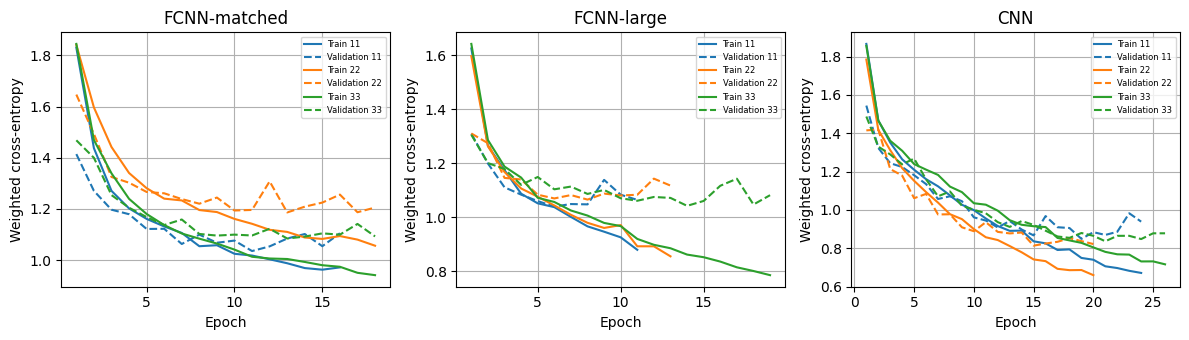

In [29]:
fig,axs=plt.subplots(1,3,figsize=(12,3.5))
for ax,name in zip(axs,['FCNN-matched','FCNN-large','CNN']):
    for j,seed in enumerate(SEEDS):
        h=pd.read_csv(RESULT/f'baseline_{name}_{seed}_history.csv')
        ax.plot(h.epoch,h.train_loss,color=f'C{j}',label=f'Train {seed}')
        ax.plot(h.epoch,h.val_loss,color=f'C{j}',ls='--',label=f'Validation {seed}')
    ax.set(xlabel='Epoch',ylabel='Weighted cross-entropy',title=name);ax.legend(fontsize=6)
savefig('training_curves')

#### Which classes are confused?

For each model, I use the seed with the lowest validation loss to show the confusion matrix. I did not choose it using test accuracy. The numbers give the image counts, while the colours show the fraction within each true class.

Class 5 has only two test images. Getting one more of them right would change its recall by 50 percentage points, so I would be careful about drawing conclusions for this class.

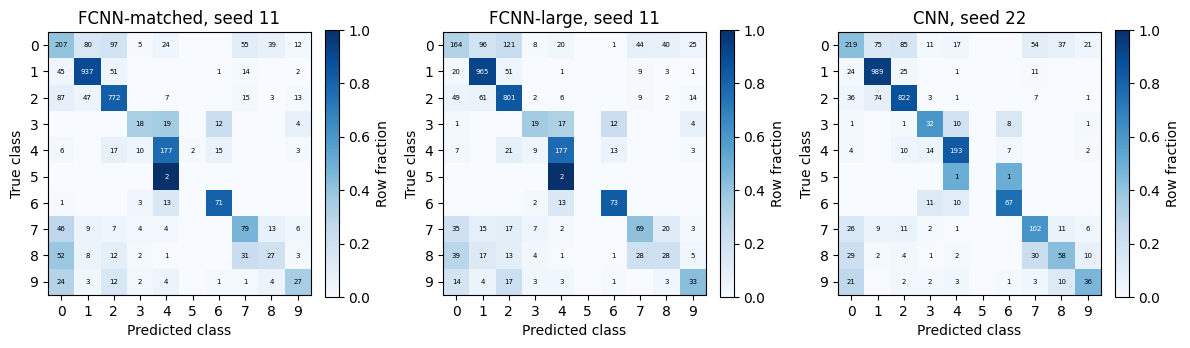

In [30]:
best_seeds={name:int(base[base.model==name].sort_values('best_val_loss').iloc[0].seed) for name in BUILD}
savejson(best_seeds,'representative_seeds.json')
fig,axs=plt.subplots(1,3,figsize=(12,3.8))
for ax,name in zip(axs,['FCNN-matched','FCNN-large','CNN']):
    p=probabilities[(name,best_seeds[name],'baseline')];cm=confusion_matrix(ytest,p.argmax(1),labels=range(10))
    pd.DataFrame(cm).to_csv(RESULT/f'confusion_{name}.csv',index=False)
    norm=cm/cm.sum(axis=1,keepdims=True)
    ax.grid(False)
    im=ax.imshow(norm,cmap='Blues',vmin=0,vmax=1)
    for i in range(10):
        for j in range(10):
            if cm[i,j]:ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=5,color='white' if norm[i,j]>.55 else 'black')
    ax.set(xticks=range(10),yticks=range(10),xlabel='Predicted class',ylabel='True class',title=f'{name}, seed {best_seeds[name]}')
    fig.colorbar(im,ax=ax,fraction=.046,label='Row fraction')
savefig('confusion_matrices')

In [31]:
cm = pd.read_csv(RESULT/'confusion_CNN.csv').to_numpy()
display(Markdown(f"For the representative CNN, classes 1 and 2 are confused in **{cm[1,2]+cm[2,1]}** cases. "
    f"Classes 7–9 are confused with one another in **{int(cm[7:10,7:10].sum()-np.trace(cm[7:10,7:10]))}** cases. "
    "These are the neighbouring categories I expected to be difficult in Part 2.2. The mistakes could be explained "
    "by faint or ambiguous structure, but I cannot conclude from this alone that the labels are wrong."))

For the representative CNN, classes 1 and 2 are confused in **99** cases. Classes 7–9 are confused with one another in **70** cases. These are the neighbouring categories I expected to be difficult in Part 2.2. The mistakes could be explained by faint or ambiguous structure, but I cannot conclude from this alone that the labels are wrong.

#### ROC curves

I chose class 1, a common smooth class, and class 7, a spiral class. These curves show what happens as I change the threshold on each class's score.

A model can rank examples of one class fairly well and still make mistakes when choosing between all ten classes. I therefore use the ROC curves alongside the confusion matrices.

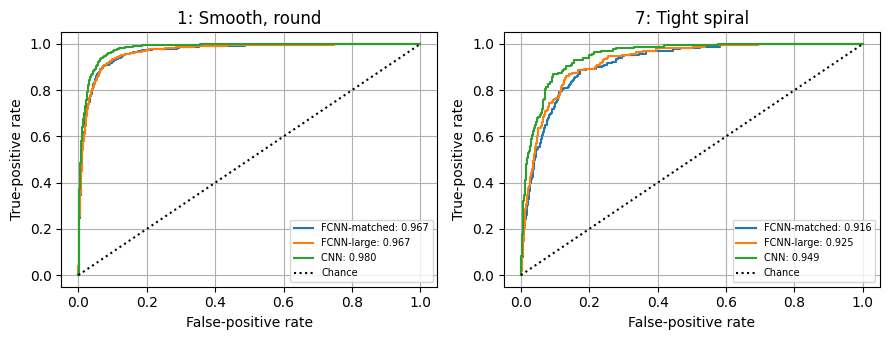

In [32]:
fig,axs=plt.subplots(1,2,figsize=(9,3.5));auc_rows=[]
for ax,c in zip(axs,[1,7]):
    for name in ['FCNN-matched','FCNN-large','CNN']:
        p=probabilities[(name,best_seeds[name],'baseline')];fpr,tpr,_=roc_curve(ytest==c,p[:,c]);area=auc(fpr,tpr)
        ax.plot(fpr,tpr,label=f'{name}: {area:.3f}');auc_rows.append(dict(model=name,cls=c,auc=area))
    ax.plot([0,1],[0,1],'k:',label='Chance');ax.set(xlabel='False-positive rate',ylabel='True-positive rate',title=f'{c}: {NAMES[c]}');ax.legend(fontsize=7)
savefig('roc');pd.DataFrame(auc_rows).to_csv(RESULT/'roc_auc.csv',index=False)

### 3.2 Shifted galaxies.

I shifted the crop by 0, 2, 4, 6 and 8 pixels without retraining the models. Each image gets one randomly chosen cardinal direction, which I keep the same across distances and models. I also keep the original sky estimates and training normalisation constants.

This changes where the galaxy appears in the crop, but it can also remove some of its outskirts or bring in new background pixels. I need to keep both effects in mind when interpreting the results.

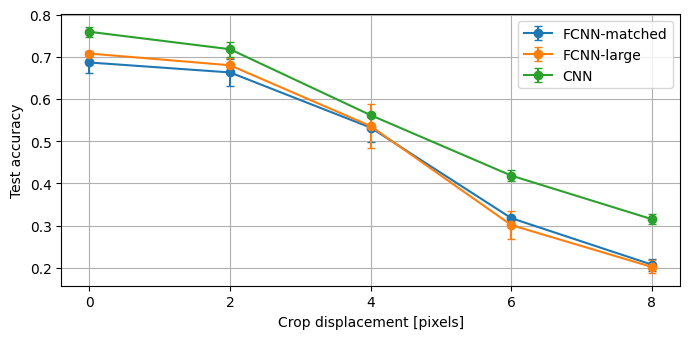

In [33]:
if MODE == 'gpu':
    directions=np.array([[0,1],[1,0],[0,-1],[-1,0]])[np.random.default_rng(2552).integers(0,4,len(test_idx))]
    np.save(RESULT/'shift_directions.npy',directions)
    shiftrows=[]
    for d in [0,2,4,6,8]:
        xshift=xtest if d==0 else preprocess(test_idx,d*directions)
        for name in BUILD:
            for seed in SEEDS:
                model=load_model(name,seed,'baseline');p=predict(model,xshift);del model
                shiftrows.append(dict(model=name,seed=seed,displacement=d,accuracy=accuracy_score(ytest,p.argmax(1)),balanced_accuracy=balanced_accuracy_score(ytest,p.argmax(1))))
    pd.DataFrame(shiftrows).to_csv(RESULT/'shift_metrics.csv',index=False)
else:
    shiftrows = pd.read_csv(RESULT/'shift_metrics.csv').to_dict('records')
df=pd.DataFrame(shiftrows);plt.figure(figsize=(7,3.5))
for name in ['FCNN-matched','FCNN-large','CNN']:
    g=df[df.model==name].groupby('displacement').accuracy.agg(['mean','std'])
    plt.errorbar(g.index,g['mean'],yerr=g['std'],marker='o',capsize=3,label=name)
plt.xlabel('Crop displacement [pixels]');plt.ylabel('Test accuracy');plt.xticks([0,2,4,6,8]);plt.legend();savefig('shift_robustness')

In [34]:
shift_means = pd.DataFrame(shiftrows).groupby(['model','displacement']).accuracy.mean().unstack()
shift_drops = (shift_means[0].to_numpy()[:,None] - shift_means) * 100
display(shift_drops.rename_axis(columns='Displacement: accuracy loss in percentage points'))
display(Markdown('I compare both the small and large shifts with my prediction in T4. '
    'Keeping a higher accuracy does not necessarily mean losing fewer points. Pooling and shared '
    'weights can help, but they cannot recover light that has left the crop.'))
small = shift_drops[2]; large = shift_drops[8]
display(Markdown(f"At two pixels the CNN loses **{small['CNN']:.2f}** points; at eight pixels it loses "
    f"**{large['CNN']:.2f}**. Its small-shift loss is "
    + ('smaller' if small['CNN'] < small.drop('CNN').min() else 'not smaller than both FCNN losses')
    + '. I therefore need to look at the whole curve when judging my prediction.'))

Displacement: accuracy loss in percentage points,0,2,4,6,8
model,,,,,
CNN,0.0,4.130967,19.747042,34.057528,44.379845
FCNN-large,0.0,2.774378,17.197062,40.626275,50.540596
FCNN-matched,0.0,2.356181,15.422277,36.862505,47.878417


I compare both the small and large shifts with my prediction in T4. Keeping a higher accuracy does not necessarily mean losing fewer points. Pooling and shared weights can help, but they cannot recover light that has left the crop.

At two pixels the CNN loses **4.13** points; at eight pixels it loses **44.38**. Its small-shift loss is not smaller than both FCNN losses. I therefore need to look at the whole curve when judging my prediction.

### 3.3 Scrambled pixels.

Here I return to the two scrambled models trained earlier. I compare them with their original seed-11 runs so I am not choosing a different baseline seed for the comparison.

The example below shows what the permutation does. All the pixel values are still there, but nearby positions no longer correspond to nearby parts of the galaxy.

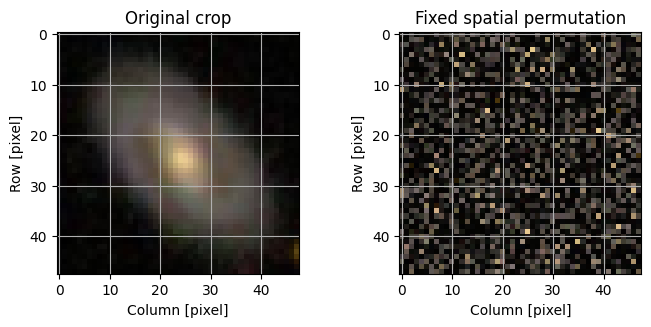

In [35]:
fig,axs=plt.subplots(1,2,figsize=(7,3.3))
a=images[train_idx[0],10:58,10:58,:]
for ax,im,title in zip(axs,[a,a.reshape(-1,3)[permutation].reshape(48,48,3)],['Original crop','Fixed spatial permutation']):
    ax.imshow(im);ax.set(xlabel='Column [pixel]',ylabel='Row [pixel]',title=title)
savefig('scrambled_example')

In [36]:
scr = metrics[metrics.tag == 'scrambled'].set_index('model')
original = base[base.seed == 11].set_index('model')
scramble_table = pd.DataFrame({'Original accuracy (%)':original.loc[scr.index,'accuracy']*100,
    'Scrambled accuracy (%)':scr.accuracy*100,
    'Accuracy change (points)':(scr.accuracy-original.loc[scr.index,'accuracy'])*100,
    'Balanced change (points)':(scr.balanced_accuracy-original.loc[scr.index,'balanced_accuracy'])*100})
display(scramble_table)
delta = scramble_table.loc['CNN','Accuracy change (points)']
display(Markdown(f"The CNN accuracy changes by **{delta:+.2f} percentage points**. "
    "I only trained one scrambled seed per model, so I would repeat this before drawing a firm conclusion. "
    "The pixel colours and intensities are still present, and the CNN still has its large dense head; "
    "these might help explain its remaining accuracy, although I have not checked which features it uses."))

,Original accuracy (%),Scrambled accuracy (%),Accuracy change (points),Balanced change (points)
model,,,,
FCNN-matched,70.838433,63.280294,-7.558140,1.950534
CNN,76.040392,73.745410,-2.294982,-5.427943


The CNN accuracy changes by **-2.29 percentage points**. I only trained one scrambled seed per model, so I would repeat this before drawing a firm conclusion. The pixel colours and intensities are still present, and the CNN still has its large dense head; these might help explain its remaining accuracy, although I have not checked which features it uses.

I expected scrambling to hurt the CNN more, but that is not what I found for this seed. CNN accuracy fell by 2.29 percentage points, compared with 7.56 points for FCNN-matched. The FCNN can represent the same functions after rearranging its first-layer weights, but that does not mean retraining will find an equally good set of weights.

The CNN's balanced accuracy fell by 5.43 points, so the effect is larger when I give every class equal weight. I would repeat the scrambled experiment with more seeds before deciding how consistent these differences are.

Lecture 5's CNN slides (23–25) also show that the effect of scrambling varies between datasets. My Galaxy10 results do not have to match the CIFAR10 example.

## Optional extensions

### B2. Robustness to noise.

I added Gaussian noise to the raw test images before preprocessing. I used standard deviations of k times the original robust sky estimate, with k = 0, 1, 2 and 4.

After adding the noise, I clip the values to the allowed range, estimate the sky again, and apply the same crop and training normalisation. I reuse the same underlying random noise values for each strength and model. I do not retrain the models for this experiment.

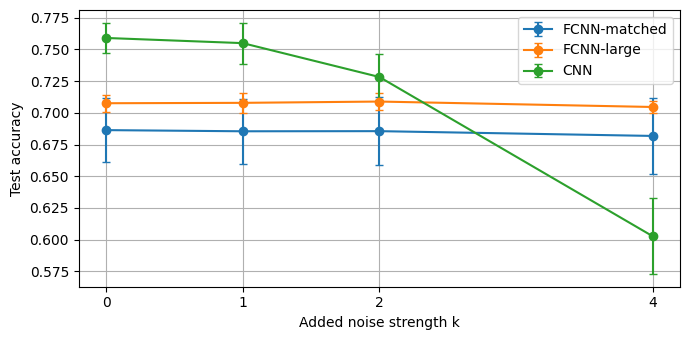

All required experiments and optional B2 completed.


In [38]:
if MODE == 'gpu':
    noise_rows=[]
    for k in [0,1,2,4]:
        rng=np.random.default_rng(2553)
        raw=images[test_idx].astype(np.float32)
        raw=np.clip(raw+rng.standard_normal(raw.shape,dtype=np.float32)*np.maximum(noise_mad[test_idx],floor)[:,None,None,:]*k,0,255)
        bg=np.median(raw[:,border,:],axis=1)
        arr=(raw[:,10:58,10:58,:]-bg[:,None,None,:]-mu)/sd
        xn=torch.from_numpy(arr.transpose(0,3,1,2).astype(np.float32, copy=True));del raw,arr
        for name in BUILD:
            for seed in SEEDS:
                model=load_model(name,seed,'baseline');p=predict(model,xn);del model
                noise_rows.append(dict(model=name,seed=seed,k=k,accuracy=accuracy_score(ytest,p.argmax(1)),balanced_accuracy=balanced_accuracy_score(ytest,p.argmax(1))))
    pd.DataFrame(noise_rows).to_csv(RESULT/'noise_metrics.csv',index=False)
else:
    noise_rows = pd.read_csv(RESULT/'noise_metrics.csv').to_dict('records')
df=pd.DataFrame(noise_rows);plt.figure(figsize=(7,3.5))
for name in ['FCNN-matched','FCNN-large','CNN']:
    g=df[df.model==name].groupby('k').accuracy.agg(['mean','std'])
    plt.errorbar(g.index,g['mean'],yerr=g['std'],marker='o',capsize=3,label=name)
plt.xlabel('Added noise strength k');plt.ylabel('Test accuracy');plt.xticks([0,1,2,4]);plt.legend();savefig('noise_robustness')
print('All required experiments and optional B2 completed.',flush=True)

In [39]:
noise_means = pd.DataFrame(noise_rows).groupby(['model','k']).accuracy.mean().unstack()
noise_loss = (noise_means[0] - noise_means[4]) * 100
display(pd.DataFrame({'Accuracy at k=0 (%)':noise_means[0]*100,
    'Accuracy at k=4 (%)':noise_means[4]*100, 'Loss (points)':noise_loss}))
display(Markdown(f"The largest loss at k=4 is **{noise_loss.idxmax()} ({noise_loss.max():.2f} points)**. "
    "From T7, I would expect max pooling to pick up some positive noise fluctuations. However, this test does not "
    "separate that effect from the learned filters and dense head. The Gaussian noise I added "
    "lets me test extra noise in a controlled way, but it does not capture all survey noise, and clipping changes the added distribution."))

,Accuracy at k=0 (%),Accuracy at k=4 (%),Loss (points)
model,,,
CNN,75.907793,60.261118,15.646675
FCNN-large,70.756834,70.461036,0.295798
FCNN-matched,68.635251,68.176255,0.458996


The largest loss at k=4 is **CNN (15.65 points)**. From T7, I would expect max pooling to pick up some positive noise fluctuations. However, this test does not separate that effect from the learned filters and dense head. The Gaussian noise I added lets me test extra noise in a controlled way, but it does not capture all survey noise, and clipping changes the added distribution.

The spectra notebook trains and tests at the chosen noise level. In my experiment, the models were trained on the original images and only the test images get extra noise. I would not expect these two experiments to answer exactly the same question about noise robustness.

## Part 4: Discussion (10 points)

### (a)

I have put the accuracy and timing results together below. For time to the common target, the average only includes successful runs; the last column shows how many reached it.

In [40]:
final_table = pd.DataFrame([{'Model':name, 'Accuracy (%)':ms(g.accuracy,100),
    'Balanced (%)':ms(g.balanced_accuracy,100), 'Parameters':int(g.parameters.iloc[0]),
    'MACs':int(g.macs.iloc[0]), 'Seconds/epoch':ms(g.mean_epoch_seconds),
    'Seconds/target':ms(g.target_seconds), 'Target reached':f'{g.target_seconds.notna().sum()}/3'}
    for name,g in base.groupby('model',sort=False)])
display(final_table)
final_table.to_csv(RESULT/'report_comparison.csv',index=False)
fast = base.groupby('model').mean_epoch_seconds.mean()
display(Markdown(f"**{acc.idxmax()}** has the highest mean accuracy, while **{fast.idxmin()}** has "
    "the shortest mean epoch. I therefore get different answers depending on whether I compare accuracy or training speed. "
    "The other experiments show whether that accuracy advantage survives changes to the images."))

,Model,Accuracy (%),Balanced (%),Parameters,MACs,Seconds/epoch,Seconds/target,Target reached
0,FCNN-matched,68.64 ± 2.54,49.16 ± 2.09,168162,168064,0.52 ± 0.02,6.23,1/3
1,FCNN-large,70.76 ± 0.68,52.99 ± 1.94,1803914,1803520,0.55 ± 0.00,6.25 ± 2.12,3/3
2,CNN,75.91 ± 1.21,59.47 ± 0.11,171754,6451840,1.00 ± 0.05,10.74 ± 2.64,3/3


**CNN** has the highest mean accuracy, while **FCNN-matched** has the shortest mean epoch. I therefore get different answers depending on whether I compare accuracy or training speed. The other experiments show whether that accuracy advantage survives changes to the images.

The CNN reached the highest mean test accuracy, approximately 75.91%, compared with 68.64% for FCNN-matched and 70.76% for FCNN-large. Its balanced accuracy was also higher. However, the larger FCNN reached the common target in less time, so the most accurate model was not the fastest one for this target.

### (b)

I expected the CNN's use of nearby pixels and shared filters to help with these images. It did retain more accuracy at large crop shifts, but its drop at two pixels was larger than either FCNN's. Scrambling also hurt the matched FCNN more in the seed I tested. The results therefore only partly follow my original expectations. I have not looked at the learned filters, so I cannot say which galaxy features the CNN actually used.

Adding noise gave a different result again. At k = 4, the CNN lost about 15.65 accuracy points, while both FCNNs lost less than half a point. The CNN's higher accuracy on the original images did not make it more robust to every change in the data.

### (c)

If I only had the five magnitudes u, g, r, i and z, I would start with an FCNN. There would be no two-dimensional image for a 2D CNN to work on. Although the bands have a wavelength order, moving a filter between these five distinct measurements assumes that the same pattern has the same meaning in different bands. I would want a reason for making that assumption before using a 1D CNN.

### (d)

I would next look more closely at ambiguous training labels and the rare classes, and try to obtain more examples there. Noise, resolution and clipping also limit what is visible in the images. I would test any changes to preprocessing or the model on the validation set, leaving the test set out of those decisions.